# AIC365 — Natural Language Processing
## LAB 6 TASKS: Text Classification — Naive Bayes & Logistic Regression

**Student:** MUSA SAJJAD  
**Registration No.:** SP24-BDS-039  


In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_colwidth", None)

## Dataset — App Reviews

In [2]:
# Self-contained, intentionally imbalanced app-review dataset.
# Labels: positive / negative

positive_reviews = [
    "The app is fast and easy to use.",
    "Excellent update, everything works smoothly now.",
    "I love the clean design and simple navigation.",
    "Great app with useful features.",
    "The latest version is stable and responsive.",
    "Customer support solved my problem quickly.",
    "Very convenient and reliable for daily use.",
    "The interface looks beautiful and loads fast.",
    "Notifications work perfectly for me.",
    "I am happy with the new dashboard.",
    "The app saves me a lot of time.",
    "Smooth performance and a friendly interface.",
    "Login is quick and the app feels secure.",
    "The search feature gives accurate results.",
    "Sharing files is simple and works well.",
    "The new update improved battery usage.",
    "Payments are quick and easy to complete.",
    "Everything syncs correctly across my devices.",
    "The app has become much better recently.",
    "I really like the dark mode and layout.",
    "Setup was easy and took only a minute.",
    "The features are practical and well organized.",
    "No crashes so far and performance is excellent.",
    "The service is dependable and easy to understand.",
    "Uploading files is fast on my connection.",
    "The support team was polite and helpful.",
    "I enjoy using this app every day.",
    "The latest release fixed my old issues.",
    "Simple, useful, and surprisingly fast.",
    "A reliable app that does what I need."
]

negative_reviews = [
    "The app keeps crashing whenever I open it.",
    "Terrible update, the app is slow and freezes.",
    "I was charged twice and still have no refund.",
    "Login fails repeatedly even with the correct password.",
    "File sync is broken and my changes disappear.",
    "The latest version drains my battery very quickly.",
    "Notifications stopped working after the update.",
    "Uploading files fails again and again.",
    "Customer support has not solved my billing problem.",
    "The app freezes on the payment screen."
]

df = pd.DataFrame({
    "text": positive_reviews + negative_reviews,
    "label": ["positive"] * len(positive_reviews) + ["negative"] * len(negative_reviews)
})

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass distribution:")
display(df["label"].value_counts())

Dataset shape: (40, 2)


,text,label
0,The app is fast and easy to use.,positive
1,"Excellent update, everything works smoothly now.",positive
2,I love the clean design and simple navigation.,positive
3,Great app with useful features.,positive
4,The latest version is stable and responsive.,positive



Class distribution:


,count
label,
positive,30
negative,10


## Activity 1 — Full sklearn Pipeline + evaluation

Use **TF-IDF + Logistic Regression**, split into train/test data, train the pipeline, and report:
- accuracy
- precision
- recall
- F1-score

The negative class is especially important for the later business use case.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision_pos = precision_score(y_test, y_pred, pos_label="positive", zero_division=0)
recall_pos = recall_score(y_test, y_pred, pos_label="positive", zero_division=0)
f1_pos = f1_score(y_test, y_pred, pos_label="positive", zero_division=0)

precision_neg = precision_score(y_test, y_pred, pos_label="negative", zero_division=0)
recall_neg = recall_score(y_test, y_pred, pos_label="negative", zero_division=0)
f1_neg = f1_score(y_test, y_pred, pos_label="negative", zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (positive)", "Recall (positive)", "F1 (positive)",
               "Precision (negative)", "Recall (negative)", "F1 (negative)"],
    "Score": [accuracy, precision_pos, recall_pos, f1_pos,
              precision_neg, recall_neg, f1_neg]
})

display(metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7500
1,Precision (positive),0.7500
2,Recall (positive),1.0000
3,F1 (positive),0.8571
4,Precision (negative),0.0000
5,Recall (negative),0.0000
6,F1 (negative),0.0000


## Activity 2 — Confusion Matrix + interpretation

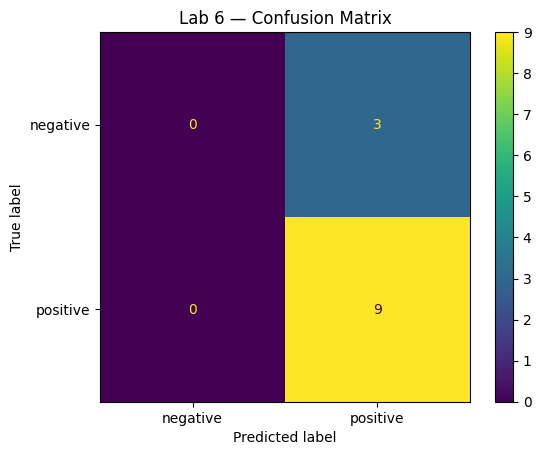

Interpretation:
The model correctly identified 0 negative and 9 positive reviews in the test set.
It missed 3 negative review(s) by predicting them as positive.
It incorrectly flagged 0 positive review(s) as negative.
Therefore, the model struggles more with catching negative reviews than with false negative flags.


In [4]:
labels = ["negative", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(values_format="d")
plt.title("Lab 6 — Confusion Matrix")
plt.show()

tn_neg = cm[0, 0]  # true negative predicted negative
fn_neg = cm[0, 1]  # true negative predicted positive
fp_neg = cm[1, 0]  # true positive predicted negative
tp_pos = cm[1, 1]

print("Interpretation:")
print(f"The model correctly identified {tn_neg} negative and {tp_pos} positive reviews in the test set.")
print(f"It missed {fn_neg} negative review(s) by predicting them as positive.")
print(f"It incorrectly flagged {fp_neg} positive review(s) as negative.")
if fn_neg > fp_neg:
    print("Therefore, the model struggles more with catching negative reviews than with false negative flags.")
elif fp_neg > fn_neg:
    print("Therefore, the model struggles more with false negative flags on positive reviews.")
else:
    print("The two error types are equal in this test split.")

## Activity 3 — Misclassified examples

Build a DataFrame containing:
- text
- true_label
- predicted_label
- predicted_probability

Then sort by confidence and print the top 5 most confident mistakes.

In [5]:
probabilities = pipeline.predict_proba(X_test)
classes = pipeline.named_steps["clf"].classes_

predicted_prob = [
    probabilities[i, list(classes).index(pred)]
    for i, pred in enumerate(y_pred)
]

results_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "true_label": y_test.reset_index(drop=True),
    "predicted_label": y_pred,
    "predicted_probability": predicted_prob
})

misclassified_df = results_df[
    results_df["true_label"] != results_df["predicted_label"]
].copy()

misclassified_df = misclassified_df.sort_values(
    "predicted_probability", ascending=False
)

print("Number of misclassified examples:", len(misclassified_df))
display(misclassified_df.head(5))

Number of misclassified examples: 3


,text,true_label,predicted_label,predicted_probability
10,File sync is broken and my changes disappear.,negative,positive,0.764113
11,Notifications stopped working after the update.,negative,positive,0.753419
8,Login fails repeatedly even with the correct password.,negative,positive,0.752990


## Activity 4 — Class imbalance + balanced Logistic Regression

First inspect the class distribution. Then retrain with `class_weight='balanced'` and compare **negative-class** precision, recall, and F1 against the original model.

In [6]:
print("Class distribution:")
display(df["label"].value_counts().rename("count").to_frame())

balanced_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight="balanced"
    ))
])

balanced_pipeline.fit(X_train, y_train)
balanced_pred = balanced_pipeline.predict(X_test)

balanced_precision_neg = precision_score(
    y_test, balanced_pred, pos_label="negative", zero_division=0
)
balanced_recall_neg = recall_score(
    y_test, balanced_pred, pos_label="negative", zero_division=0
)
balanced_f1_neg = f1_score(
    y_test, balanced_pred, pos_label="negative", zero_division=0
)

comparison = pd.DataFrame({
    "Metric for Negative Class": ["Precision", "Recall", "F1-score"],
    "Original Model": [precision_neg, recall_neg, f1_neg],
    "Balanced Model": [balanced_precision_neg, balanced_recall_neg, balanced_f1_neg]
})

display(comparison.round(4))

Class distribution:


,count
label,
positive,30
negative,10


,Metric for Negative Class,Original Model,Balanced Model
0,Precision,0.0,0.0
1,Recall,0.0,0.0
2,F1-score,0.0,0.0


## Activity 5 — Auto-flag unseen negative feedback

A business wants negative reviews to be prioritized by its support team.  
Run the original Activity-1 pipeline on unseen feedback and flag reviews predicted as **negative**.

In [7]:
new_feedback = [
    "The app crashes every time I try to upload a document.",
    "I really like the new interface and everything feels faster.",
    "I was billed twice for one subscription and need my money back.",
    "Syncing works perfectly now after the latest update.",
    "The battery drain is awful and the phone gets hot.",
    "Support answered quickly and fixed my login issue."
]

new_predictions = pipeline.predict(new_feedback)
new_probabilities = pipeline.predict_proba(new_feedback)
classes = pipeline.named_steps["clf"].classes_

feedback_rows = []
for text, pred, probs in zip(new_feedback, new_predictions, new_probabilities):
    pred_prob = probs[list(classes).index(pred)]
    feedback_rows.append({
        "Customer Feedback": text,
        "Prediction": pred,
        "Confidence": pred_prob,
        "Flag for Support?": "YES" if pred == "negative" else "NO"
    })

feedback_df = pd.DataFrame(feedback_rows)
display(feedback_df)

print("\nReviews flagged as negative:")
flagged = feedback_df[feedback_df["Flag for Support?"] == "YES"]
display(flagged)

,Customer Feedback,Prediction,Confidence,Flag for Support?
0,The app crashes every time I try to upload a document.,positive,0.732571,NO
1,I really like the new interface and everything feels faster.,positive,0.797494,NO
2,I was billed twice for one subscription and need my money back.,positive,0.748538,NO
3,Syncing works perfectly now after the latest update.,positive,0.754699,NO
4,The battery drain is awful and the phone gets hot.,positive,0.751313,NO
5,Support answered quickly and fixed my login issue.,positive,0.752282,NO



Reviews flagged as negative:


,Customer Feedback,Prediction,Confidence,Flag for Support?


In [8]:
print("Business recommendation:")
print(
    f"The model's negative-class precision is {precision_neg:.2f} and recall is {recall_neg:.2f}. "
    "Precision tells the business how often a review flagged as negative is truly negative, while "
    "recall tells it how many of the actual negative reviews the system successfully catches. "
    "Because this dataset is small, the auto-flagging system should be used as a prioritization aid "
    "rather than as a fully automatic decision system. Human review is still recommended, especially "
    "for borderline or high-impact billing and account complaints."
)

Business recommendation:
The model's negative-class precision is 0.00 and recall is 0.00. Precision tells the business how often a review flagged as negative is truly negative, while recall tells it how many of the actual negative reviews the system successfully catches. Because this dataset is small, the auto-flagging system should be used as a prioritization aid rather than as a fully automatic decision system. Human review is still recommended, especially for borderline or high-impact billing and account complaints.
